1.Pré-Processamento de Dados




In [ ]:
import pandas as pd

caminho_arquivo = 'RTA Dataset.csv'

df = pd.read_csv(caminho_arquivo)

# Substitui os valores 'na' e 'Unknown' por valores nulos (NaN)
df.replace(['na', 'Unknown'], pd.NA, inplace=True)

# Verifica a contagem de valores nulos e valores 'na'/'Unknown' em cada coluna
valores_ausentes = df.isnull().sum()
valores_na_unknown = (df == 'na').sum() + (df == 'Unknown').sum()

# Exibe a contagem total de valores nulos, 'na' e 'Unknown' em cada coluna
total_valores_ausentes = valores_ausentes + valores_na_unknown
print(total_valores_ausentes)

Time                              0
Day_of_week                       0
Age_band_of_driver             1548
Sex_of_driver                   178
Educational_level               841
Vehicle_driver_relation         593
Driving_experience              829
Type_of_vehicle                 950
Owner_of_vehicle                482
Service_year_of_vehicle        6811
Defect_of_vehicle              4427
Area_accident_occured           261
Lanes_or_Medians                442
Road_allignment                 142
Types_of_Junction              1078
Road_surface_type               172
Road_surface_conditions           0
Light_conditions                  0
Weather_conditions              292
Type_of_collision               169
Number_of_vehicles_involved       0
Number_of_casualties              0
Vehicle_movement                396
Casualty_class                 4443
Sex_of_casualty                4443
Age_band_of_casualty           4443
Casualty_severity              4443
Work_of_casuality           

1.1 substituir valores em falta

In [ ]:
colunas_com_faltas_menos_600 = [
    'Sex_of_driver', 'Vehicle_driver_relation', 'Owner_of_vehicle',
    'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Road_surface_type', 'Weather_conditions',
    'Type_of_collision', 'Vehicle_movement', 'Cause_of_accident']

# Elimina as linhas onde há valores em falta nas colunas especificadas
df_limpo = df.dropna(subset=colunas_com_faltas_menos_600)

# Verifica o resultado
print(df_limpo.isnull().sum())
print(df_limpo.shape)



Time                              0
Day_of_week                       0
Age_band_of_driver             1201
Sex_of_driver                     0
Educational_level               291
Vehicle_driver_relation           0
Driving_experience              278
Type_of_vehicle                 687
Owner_of_vehicle                  0
Service_year_of_vehicle        5143
Defect_of_vehicle              3223
Area_accident_occured             0
Lanes_or_Medians                  0
Road_allignment                   0
Types_of_Junction               884
Road_surface_type                 0
Road_surface_conditions           0
Light_conditions                  0
Weather_conditions                0
Type_of_collision                 0
Number_of_vehicles_involved       0
Number_of_casualties              0
Vehicle_movement                  0
Casualty_class                 3482
Sex_of_casualty                3482
Age_band_of_casualty           3482
Casualty_severity              3482
Work_of_casuality           

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Substituir valores nulos por NaN
df.replace(['na', 'Unknown'], pd.NA, inplace=True)

# Transformar strings em inteiros usando LabelEncoder
label_encoder = LabelEncoder()
for coluna in df.columns:
    if df[coluna].dtype == 'object':
        df[coluna] = label_encoder.fit_transform(df[coluna].astype(str))

# Substituir valores nulos pela mediana de cada coluna
df = df.fillna(df.median())

# Agora o DataFrame `df` contém valores nulos substituídos pela mediana de cada coluna

print(df)


       Time  Day_of_week  Age_band_of_driver  Sex_of_driver  \
0       420            1                   0              2   
1       420            1                   1              2   
2       420            1                   0              2   
3       594            3                   0              2   
4       594            3                   0              2   
...     ...          ...                 ...            ...   
12311   374            6                   1              2   
12312   476            3                   2              2   
12313   246            3                   3              2   
12314   246            3                   0              1   
12315   246            3                   0              2   

       Educational_level  Vehicle_driver_relation  Driving_experience  \
0                      1                        1                   0   
1                      5                        1                   3   
2                      5

In [ ]:
def time_string_to_float(time_string):
    """
    Convert a time string in the format HH:MM:SS to a float representation of time.
    """
    # Split the time string into hours, minutes, and seconds
    hours, minutes, seconds = map(int, time_string.split(':'))

    # Calculate the total time in hours
    time_in_hours = hours + minutes / 60 + seconds / 3600

    return time_in_hours



In [ ]:
duplicados = df[df.duplicated(keep=False)]

# Exibir os duplicados
print("\nRegistos duplicados:")
print(duplicados)




Registos duplicados:
Empty DataFrame
Columns: [Time, Day_of_week, Age_band_of_driver, Sex_of_driver, Educational_level, Vehicle_driver_relation, Driving_experience, Type_of_vehicle, Owner_of_vehicle, Service_year_of_vehicle, Defect_of_vehicle, Area_accident_occured, Lanes_or_Medians, Road_allignment, Types_of_Junction, Road_surface_type, Road_surface_conditions, Light_conditions, Weather_conditions, Type_of_collision, Number_of_vehicles_involved, Number_of_casualties, Vehicle_movement, Casualty_class, Sex_of_casualty, Age_band_of_casualty, Casualty_severity, Work_of_casuality, Fitness_of_casuality, Pedestrian_movement, Cause_of_accident, Accident_severity]
Index: []

[0 rows x 32 columns]



Contagem de Categorias:
Accident_severity
2    10415
1     1743
0      158
Name: count, dtype: int64

Distribuição das Classes (%):
Accident_severity
2    84.564794
1    14.152322
0     1.282884
Name: proportion, dtype: float64


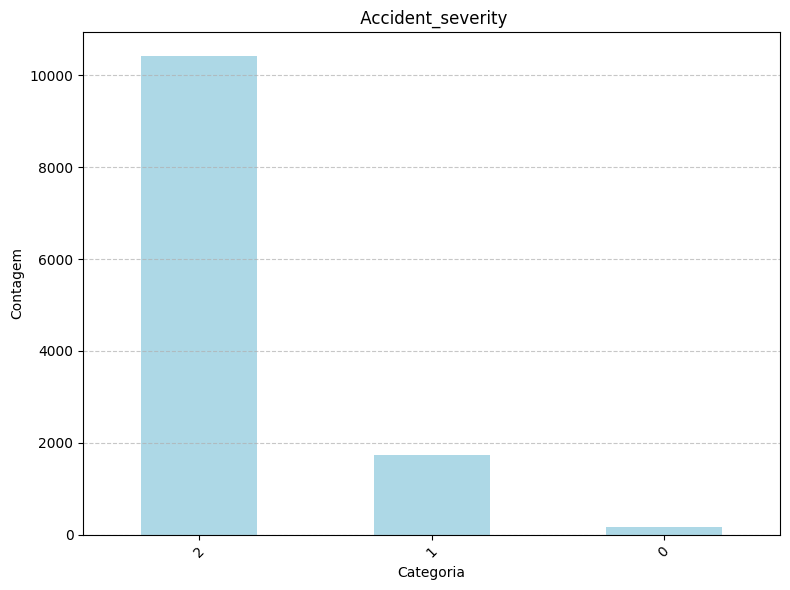

In [ ]:
#analise
import matplotlib.pyplot as plt

coluna_categorica = 'Accident_severity'

# Calcular a contagem de cada categoria na coluna categórica
contagem_categorias = df[coluna_categorica].value_counts()

# Exibir a contagem de cada categoria
print("\nContagem de Categorias:")
print(contagem_categorias)

# Exibir a distribuição das classes como porcentagem
distribuicao_classes = df[coluna_categorica].value_counts(normalize=True) * 100
print("\nDistribuição das Classes (%):")
print(distribuicao_classes)


# Definir cores para os gráficos de barra
cores = ['#ADD8E6', '#ADD8E6', '#ADD8E6']

# Plotar gráfico de barras da contagem de categorias
plt.figure(figsize=(8, 6))
contagem_categorias.plot(kind='bar', color=cores)
plt.title(' Accident_severity')
plt.xlabel('Categoria')
plt.ylabel('Contagem')
plt.xticks(rotation=45)  # Rotaciona os rótulos do eixo x para melhor legibilidade
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Adiciona linhas de grade horizontal
plt.tight_layout()  # Ajusta automaticamente o layout para evitar sobreposição de elementos
plt.show()


teste

1.2 Normalização dos Dados

In [ ]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
import pandas as pd

# Selecionar variáveis numéricas e categóricas
variaveis_numericas = df.select_dtypes(include=['float64', 'int64'])
variaveis_categoricas = df.select_dtypes(include=['object'])

# Tratar valores ausentes nas variáveis categóricas
variaveis_categoricas = variaveis_categoricas.fillna('missing')

# Normalizar variáveis numéricas
scaler = StandardScaler()
variaveis_numericas_normalizadas = pd.DataFrame(scaler.fit_transform(variaveis_numericas), columns=variaveis_numericas.columns)

# Codificar variáveis categóricas
encoder = LabelEncoder()
variaveis_categoricas_codificadas = variaveis_categoricas.apply(encoder.fit_transform)

# Concatenar variáveis categóricas codificadas e variáveis numéricas normalizadas
df_normalizado = pd.concat([variaveis_categoricas_codificadas, variaveis_numericas_normalizadas], axis=1)

# Exibir as primeiras linhas do DataFrame normalizado
print(df_normalizado.head())


    0      Time  Day_of_week  Age_band_of_driver  Sex_of_driver  \
0 NaN -0.289055    -0.961588           -0.999007       0.261925   
1 NaN -0.289055    -0.961588           -0.191567       0.261925   
2 NaN -0.289055    -0.961588           -0.999007       0.261925   
3 NaN  0.304493     0.009461           -0.999007       0.261925   
4 NaN  0.304493     0.009461           -0.999007       0.261925   

   Educational_level  Vehicle_driver_relation  Driving_experience  \
0          -2.137683                -0.508939           -1.377891   
1           0.480686                -0.508939            0.487776   
2           0.480686                -0.508939           -1.377891   
3           0.480686                -0.508939           -0.134113   
4           0.480686                -0.508939           -0.756002   

   Type_of_vehicle  Owner_of_vehicle  ...  Vehicle_movement  Casualty_class  \
0        -1.214155          0.292641  ...         -0.423961       -1.010899   
1         0.868879      

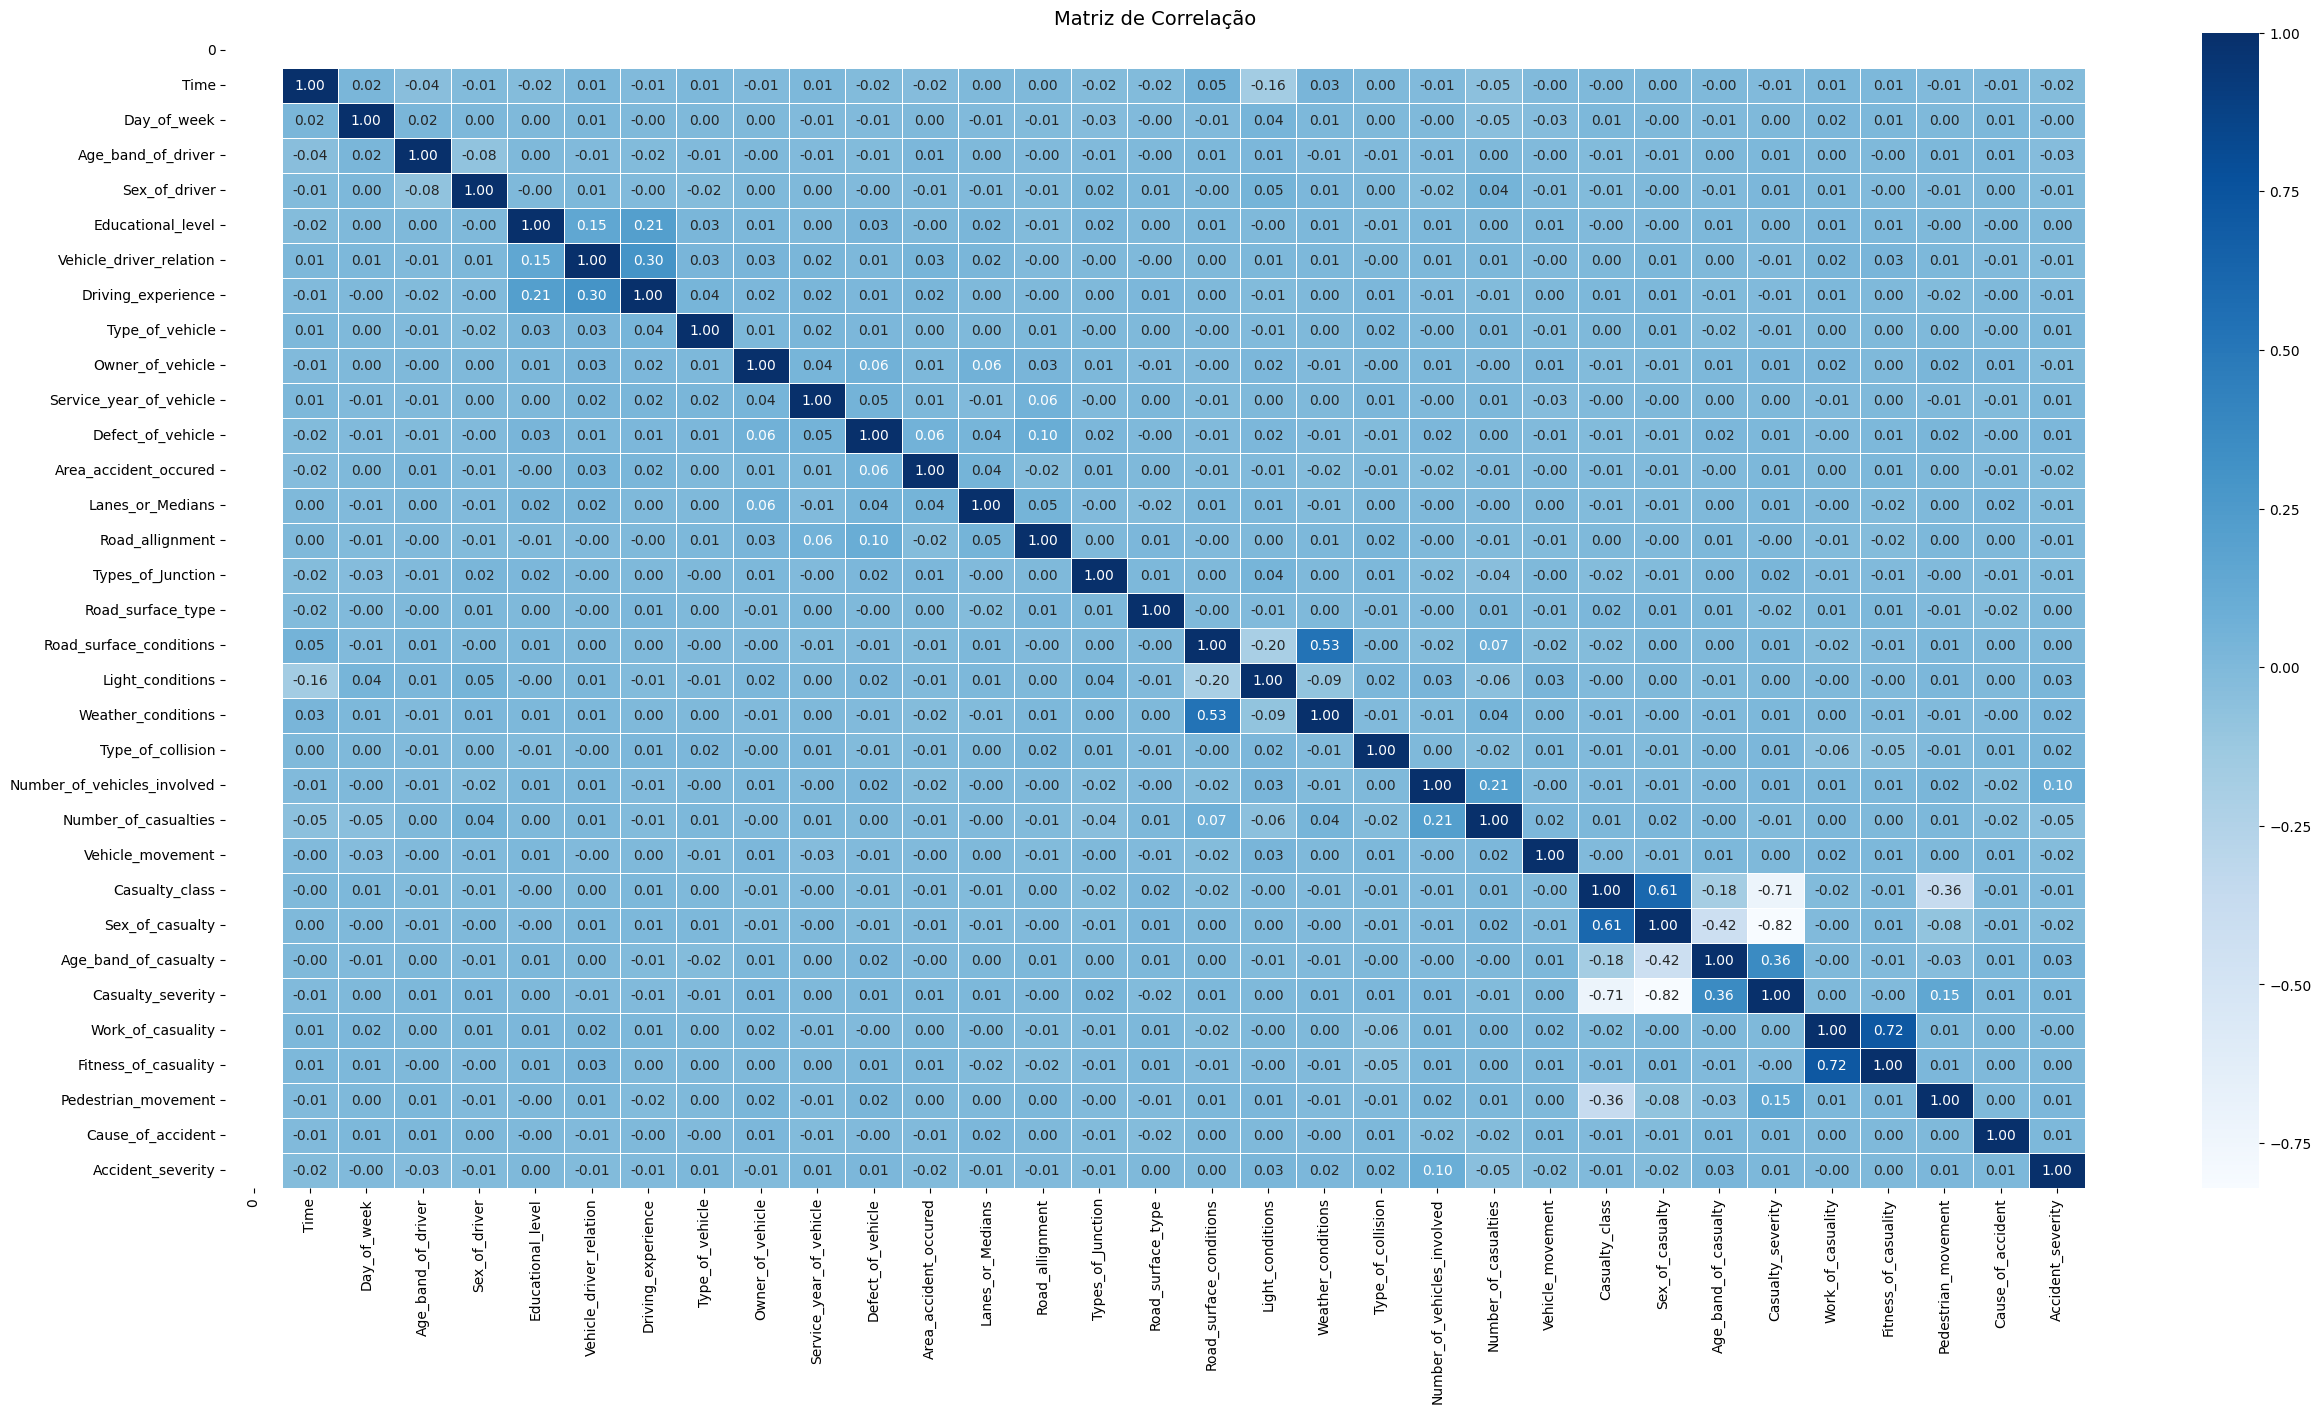

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df_normalizado.corr()

plt.figure(figsize=(30, 15))

sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt=".2f", linewidths=0.5, cbar=True)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.title('Matriz de Correlação', fontsize=14)

plt.show()



1.3.data visualization tools

Gráfico de Barras

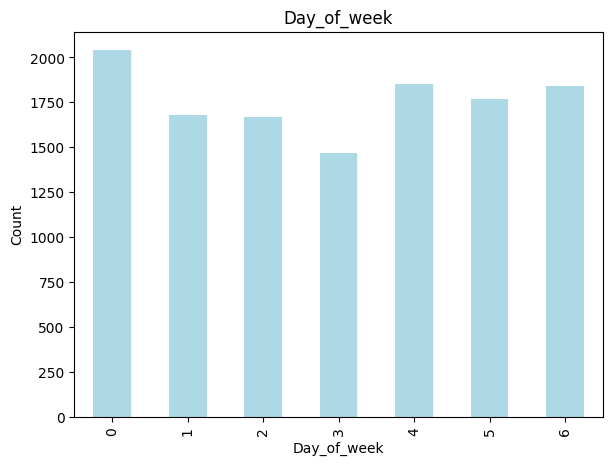

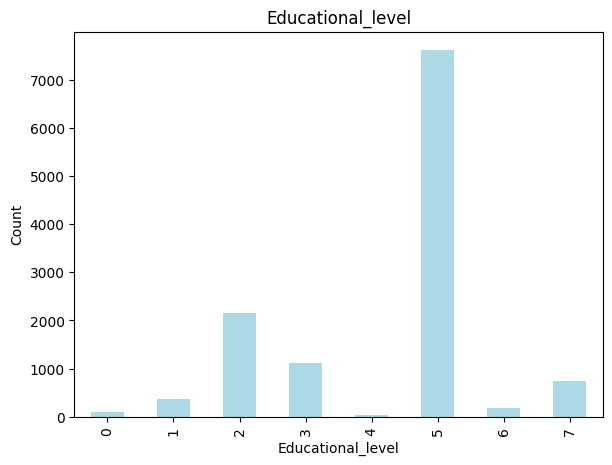

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 'Day_of_week'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Day_of_week'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Day_of_week')
plt.xlabel('Day_of_week')
plt.ylabel('Count')

# 'Educational_level'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Educational_level'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Educational_level')
plt.xlabel('Educational_level')
plt.ylabel('Count')

plt.show()



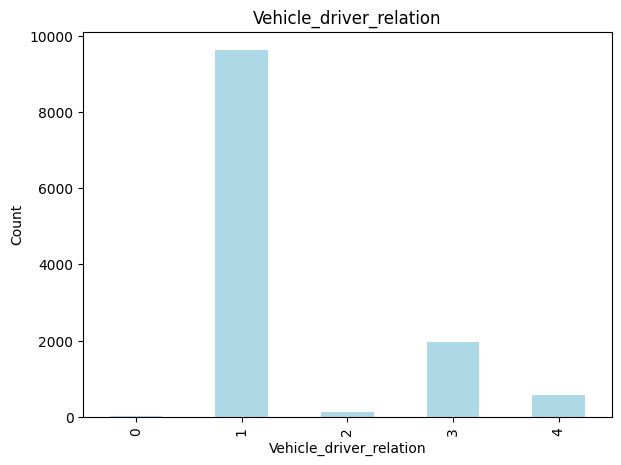

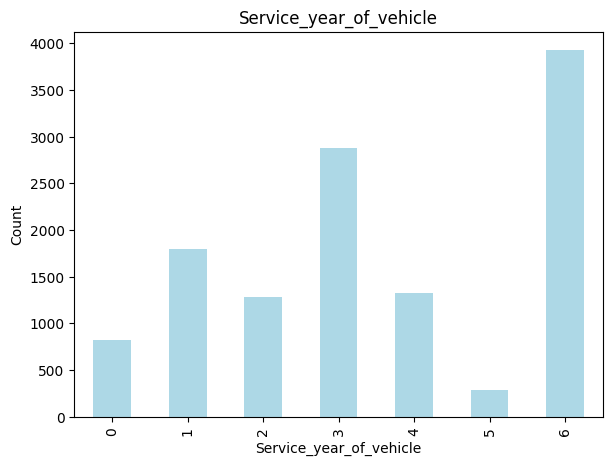

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 'Vehicle_driver_relation'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Vehicle_driver_relation'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Vehicle_driver_relation')
plt.xlabel('Vehicle_driver_relation')
plt.ylabel('Count')

# 'Service_year_of_vehicle'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Service_year_of_vehicle'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Service_year_of_vehicle')
plt.xlabel('Service_year_of_vehicle')
plt.ylabel('Count')

plt.show()  # Exibir os gráficos



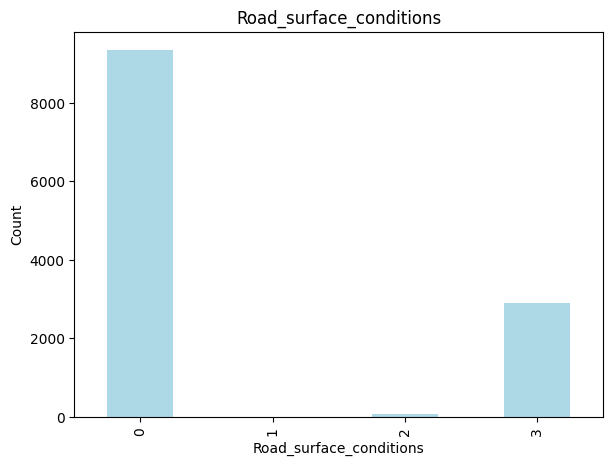

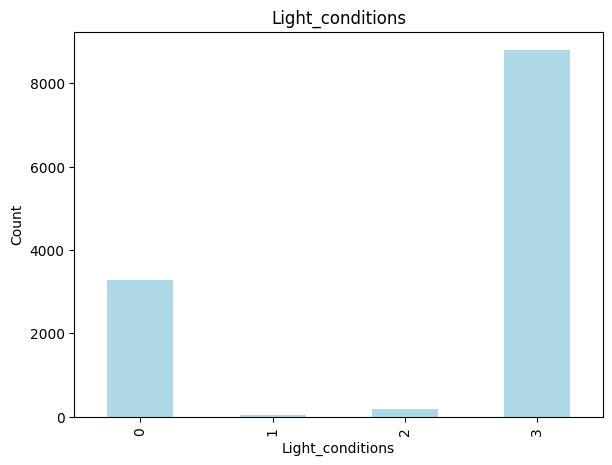

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 'Road_surface_conditions'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Road_surface_conditions'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Road_surface_conditions')
plt.xlabel('Road_surface_conditions')
plt.ylabel('Count')

# 'Light_conditions'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Light_conditions'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Light_conditions')
plt.xlabel('Light_conditions')
plt.ylabel('Count')

plt.show()  # Exibir os gráficos



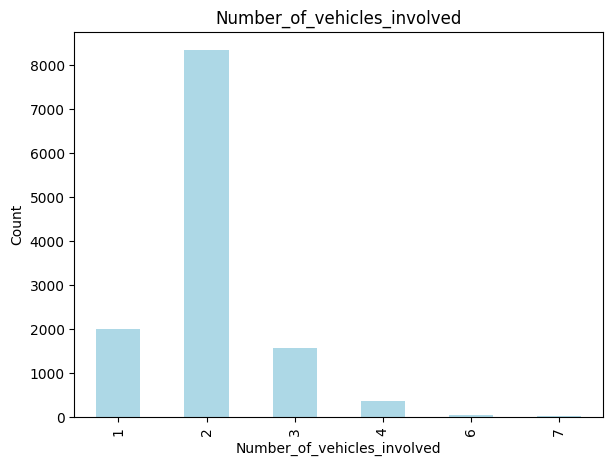

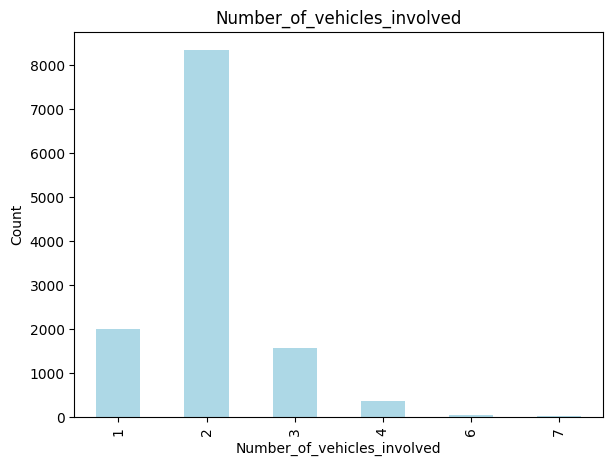

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 'Number_of_vehicles_involved'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Number_of_vehicles_involved'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Number_of_vehicles_involved')
plt.xlabel('Number_of_vehicles_involved')
plt.ylabel('Count')

# 'Number_of_vehicles_involved'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Number_of_vehicles_involved'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Number_of_vehicles_involved')
plt.xlabel('Number_of_vehicles_involved')
plt.ylabel('Count')

plt.show()  # Exibir os gráficos



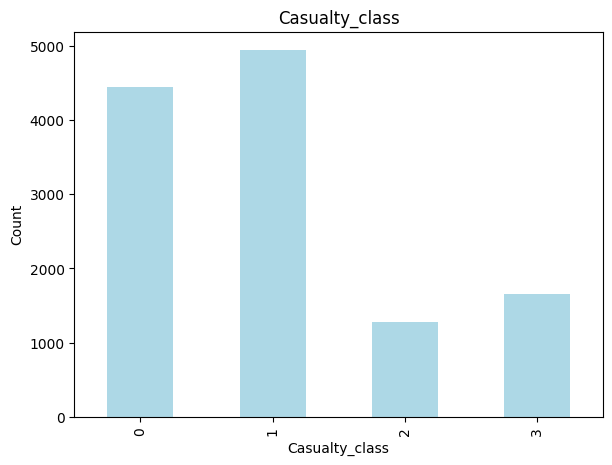

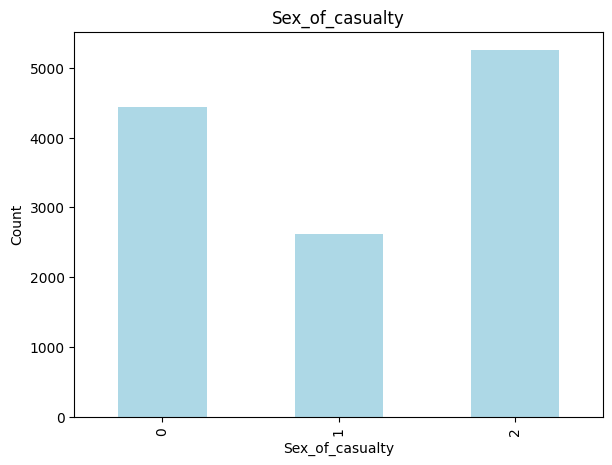

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 'Casualty_class'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Casualty_class'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Casualty_class')
plt.xlabel('Casualty_class')
plt.ylabel('Count')

# 'Sex_of_casualty'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Sex_of_casualty'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Sex_of_casualty')
plt.xlabel('Sex_of_casualty')
plt.ylabel('Count')

plt.show()  # Exibir os gráficos


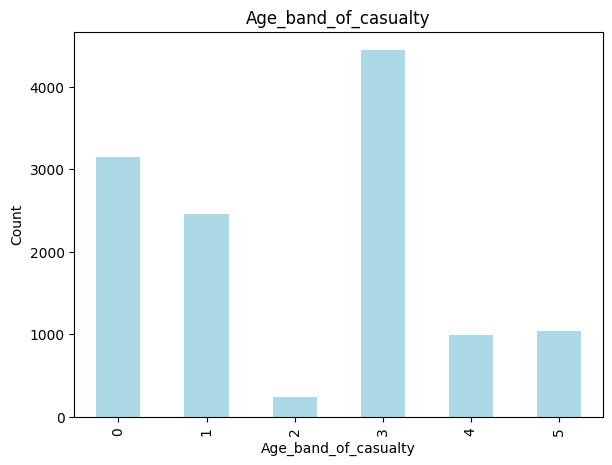

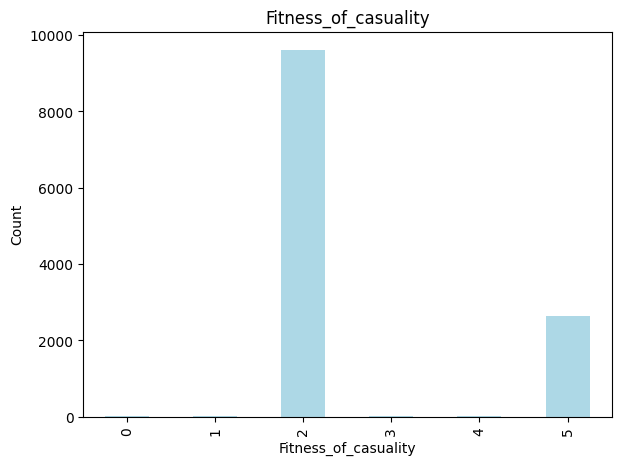

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 'Age_band_of_casualty'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Age_band_of_casualty'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Age_band_of_casualty')
plt.xlabel('Age_band_of_casualty')
plt.ylabel('Count')

# 'Fitness_of_casualty'
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
df['Fitness_of_casuality'].value_counts().sort_index().plot(kind='bar', color='lightblue')
plt.title('Fitness_of_casuality')
plt.xlabel('Fitness_of_casuality')
plt.ylabel('Count')

plt.show()  # Exibir os gráficos



pizza


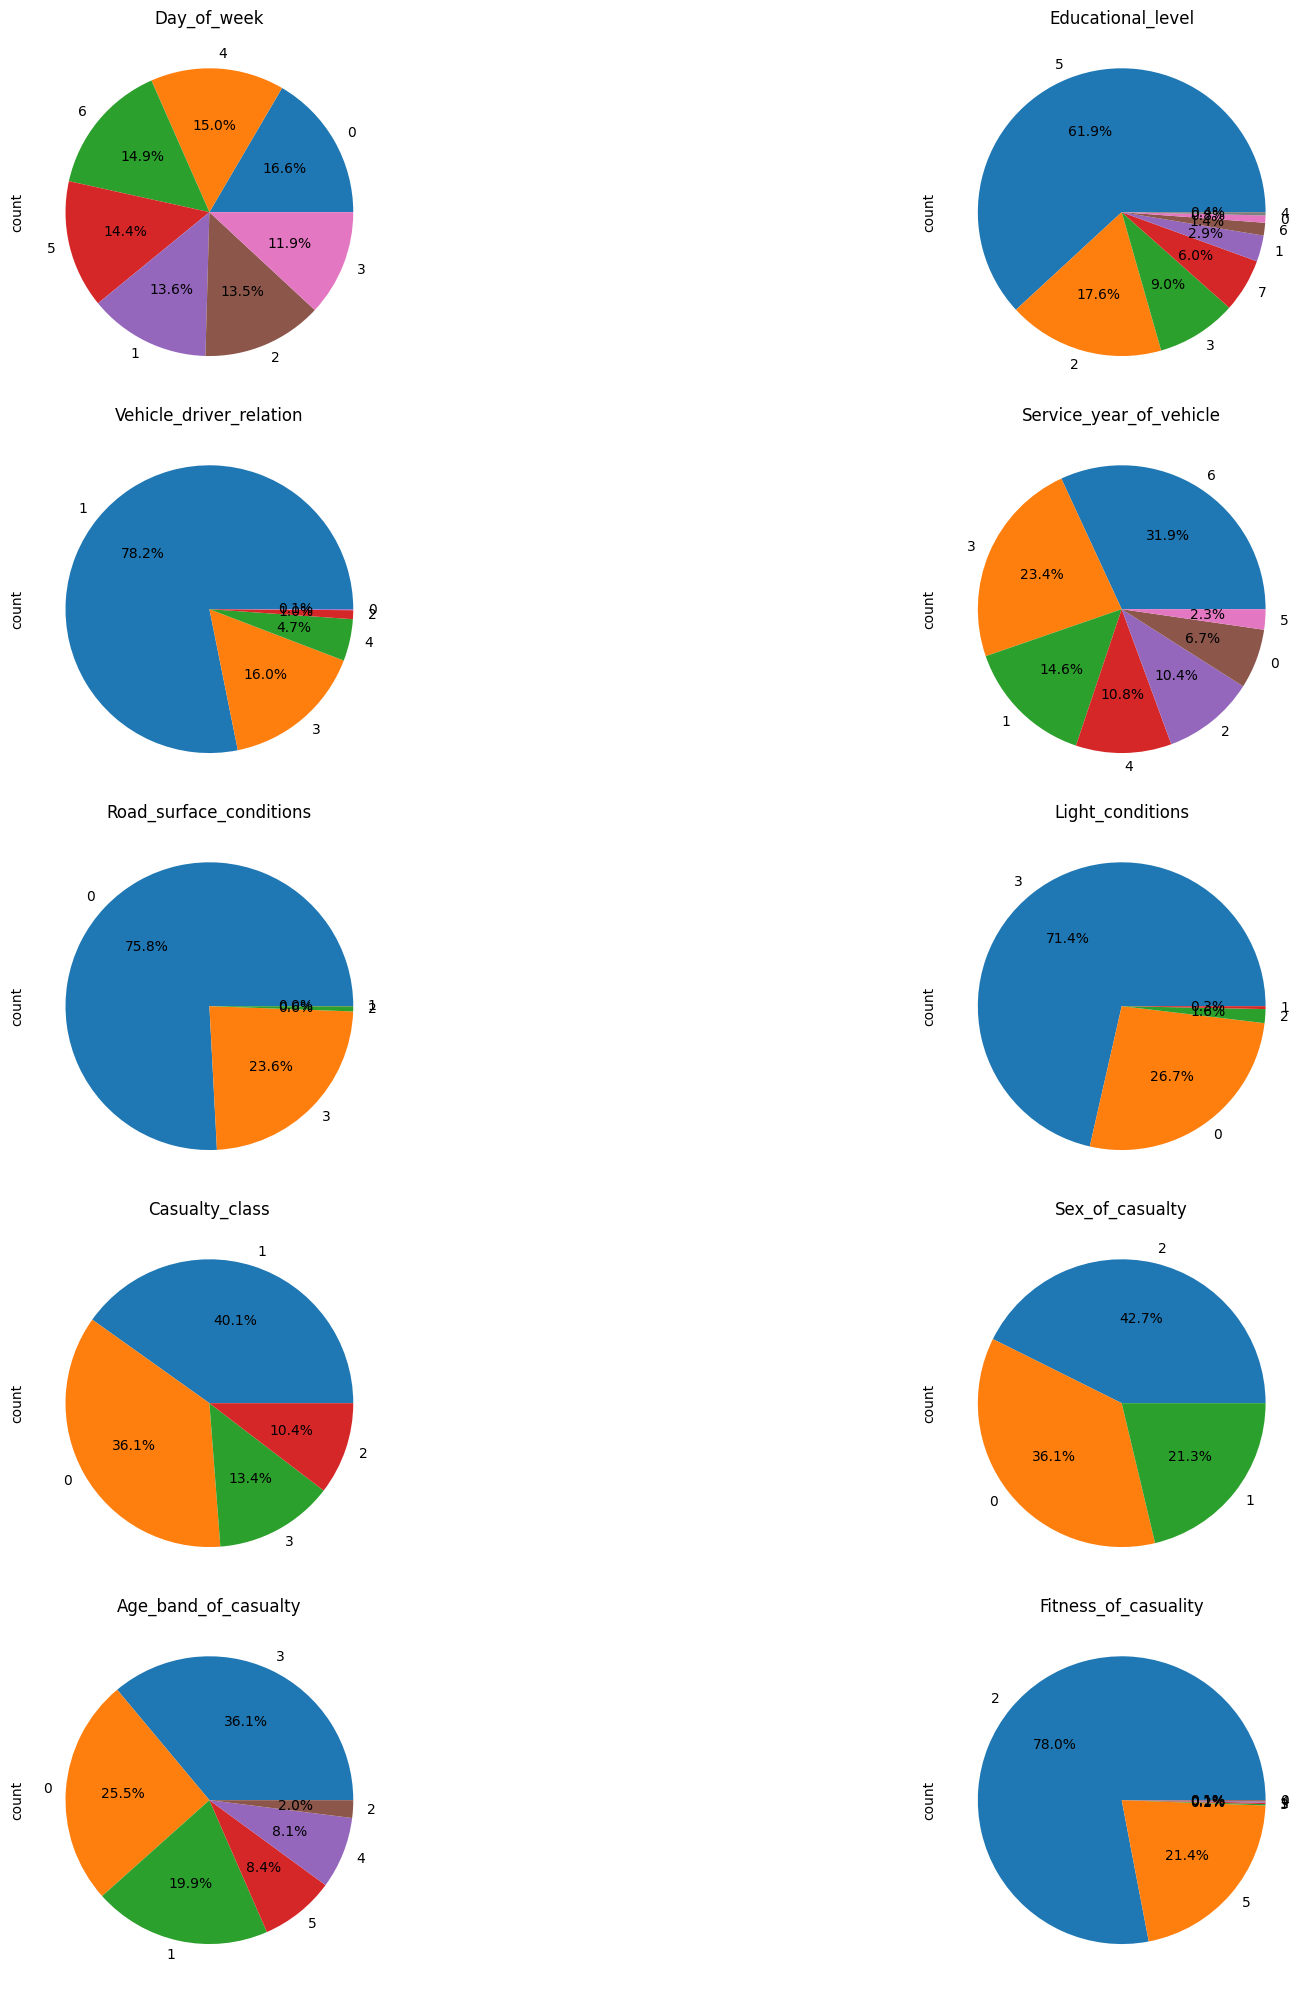

In [ ]:
import matplotlib.pyplot as plt

# Lista de variáveis categóricas que queremos visualizar
variaveis_categoricas = [
    'Day_of_week', 'Educational_level', 'Vehicle_driver_relation', 'Service_year_of_vehicle',
    'Road_surface_conditions', 'Light_conditions', 'Casualty_class', 'Sex_of_casualty',
    'Age_band_of_casualty', 'Fitness_of_casuality'
]

# Filtrar apenas as colunas categóricas que existem no DataFrame
variaveis_categoricas_existentes = [coluna for coluna in variaveis_categoricas if coluna in df.columns]

# Definir o tamanho da figura
plt.figure(figsize=(24, 20))

# Loop para criar subplots de gráficos de pizza para cada variável categórica existente
for i, coluna in enumerate(variaveis_categoricas_existentes, 1):
    plt.subplot((len(variaveis_categoricas_existentes) + 1) // 2, 2, i)
    df[coluna].value_counts().plot(kind='pie', autopct='%1.1f%%')
    plt.title(coluna)

# Ajustar layout para evitar sobreposição
plt.tight_layout()
plt.show()


1.4. Redução de variabilidade:


In [ ]:
variaveis_remover = [
    'Day_of_week', 'Educational_level', 'Vehicle_driver_relation',
    'Service_year_of_vehicle', 'Road_surface_conditions', 'Light_conditions',
    'Number_of_vehicles_involved', 'Casualty_class', 'Sex_of_casualty',
    'Age_band_of_casualty', 'Fitness_of_casuality'
]

df_limpo = df.drop(columns=variaveis_remover)
print(df_limpo)

       Time  Age_band_of_driver  Sex_of_driver  Driving_experience  \
0       420                   0              2                   0   
1       420                   1              2                   3   
2       420                   0              2                   0   
3       594                   0              2                   2   
4       594                   0              2                   1   
...     ...                 ...            ...                 ...   
12311   374                   1              2                   1   
12312   476                   2              2                   2   
12313   246                   3              2                   2   
12314   246                   0              1                   3   
12315   246                   0              2                   2   

       Type_of_vehicle  Owner_of_vehicle  Defect_of_vehicle  \
0                    0                 3                  2   
1                   11           

Modelos


SVM

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


# Aplicar o LabelEncoder à variável target
label_encoder = LabelEncoder()
df['Binary_Severity'] = label_encoder.fit_transform(df['Accident_severity'])

# Separar os dados em features e target
X = df.drop(['Accident_severity', 'Binary_Severity'], axis=1)
y = df['Binary_Severity']



In [ ]:
# Dividir os dados em conjunto de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Aplicar oversampling aos dados de treino
oversampler = RandomOverSampler()
X_train_resampled, y_train_resampled = oversampler.fit_resample(X_train, y_train)

# Treinar o modelo SVM
svc_bin = SVC(kernel='linear', C=1.0)
svc_bin.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_bin = svc_bin.predict(X_test)

# Avaliar o modelo
print('Model accuracy score for binary classification: {0:0.4f}'.format(accuracy_score(y_test, y_pred_bin)))
print(classification_report(y_test, y_pred_bin))


In [ ]:
# Separar os dados em features e target
X = df.drop('Accident_severity', axis=1)
y = df['Accident_severity']

# Dividir os dados em conjunto de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Aplicar oversampling aos dados de treino
oversampler = RandomOverSampler()
X_train_resampled, y_train_resampled = oversampler.fit_resample(X_train, y_train)

# Treinar o modelo SVM
svc_multi = SVC(kernel='linear', C=1.0)
svc_multi.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_multi = svc_multi.predict(X_test)

# Avaliar o modelo
print('Model accuracy score for multi-class classification: {0:0.4f}'.format(accuracy_score(y_test, y_pred_multi)))
print(classification_report(y_test, y_pred_multi))


 Neural Network

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


# Aplicar o LabelEncoder à variável target para classificação binária
df['Binary_Severity'] = df['Accident_severity'].apply(lambda x: 0 if x == 'Slight Injury' else 1)

# Separar os dados em features e target
X = df.drop(['Accident_severity', 'Binary_Severity'], axis=1)
y = df['Binary_Severity']

# Dividir os dados em conjunto de treino e teste usando stratify
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normalizar os dados
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:

# Aplicar OverSampling aos dados de treino
oversampler = RandomOverSampler()
X_train_resampled, y_train_resampled = oversampler.fit_resample(X_train, y_train)

# Treinar a Rede Neural com OverSampling
mlp_bin_over = MLPClassifier(random_state=42)
mlp_bin_over.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_bin_over = mlp_bin_over.predict(X_test)

# Avaliar o modelo com OverSampling
print('Model accuracy score with OverSampling: {0:0.4f}'.format(accuracy_score(y_test, y_pred_bin_over)))
print(classification_report(y_test, y_pred_bin_over))

# Aplicar UnderSampling aos dados de treino
undersampler = RandomUnderSampler()
X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train, y_train)

# Treinar a Rede Neural com UnderSampling
mlp_bin_under = MLPClassifier(random_state=42)
mlp_bin_under.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_bin_under = mlp_bin_under.predict(X_test)

# Avaliar o modelo com UnderSampling
print('Model accuracy score with UnderSampling: {0:0.4f}'.format(accuracy_score(y_test, y_pred_bin_under)))
print(classification_report(y_test, y_pred_bin_under))


In [ ]:

# Aplicar OverSampling aos dados de treino
oversampler = RandomOverSampler()
X_train_resampled, y_train_resampled = oversampler.fit_resample(X_train, y_train)

# Treinar a Rede Neural com OverSampling
mlp_multi_over = MLPClassifier(random_state=42)
mlp_multi_over.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_multi_over = mlp_multi_over.predict(X_test)

# Avaliar o modelo com OverSampling
print('Model accuracy score with OverSampling: {0:0.4f}'.format(accuracy_score(y_test, y_pred_multi_over)))
print(classification_report(y_test, y_pred_multi_over))

# Aplicar UnderSampling aos dados de treino
undersampler = RandomUnderSampler()
X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train, y_train)

# Treinar a Rede Neural com UnderSampling
mlp_multi_under = MLPClassifier(random_state=42)
mlp_multi_under.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_multi_under = mlp_multi_under.predict(X_test)

# Avaliar o modelo com UnderSampling
print('Model accuracy score with UnderSampling: {0:0.4f}'.format(accuracy_score(y_test, y_pred_multi_under)))
print(classification_report(y_test, y_pred_multi_under))


niave bayes

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.under_sampling import RandomUnderSampler

In [29]:


# Aplicar o LabelEncoder à variável target
label_encoder = LabelEncoder()
df['Binary_Severity'] = label_encoder.fit_transform(df['Accident_severity'])

# Agrupar as classes 2 e 3 em uma única classe
df['Binary_Severity'] = df['Binary_Severity'].replace({2: 1, 3: 1})

# Separar os dados em features e target
X = df.drop(['Accident_severity', 'Binary_Severity'], axis=1)
y = df['Binary_Severity']

# Padronizar as features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Dividir os dados em conjunto de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Aplicar undersampling aos dados de treino
undersampler = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train, y_train)

# Treinar o modelo Naive Bayes
nb_classifier = GaussianNB()
nb_classifier.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred = nb_classifier.predict(X_test)

# Calcular métricas de avaliação
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Formatar métricas
formatted_accuracy = '{0:0.4f}'.format(accuracy)
formatted_precision = '{0:0.4f}'.format(precision)
formatted_recall = '{0:0.4f}'.format(recall)
formatted_f1 = '{0:0.4f}'.format(f1)

# Imprimir as métricas
print('Model accuracy score for binary classification:', formatted_accuracy)
print('Precision:', formatted_precision)
print('Recall:', formatted_recall)
print('F1 Score:', formatted_f1)


Model accuracy score for binary classification: 0.9996
Precision: 0.9996
Recall: 1.0000
F1 Score: 0.9998


In [31]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

# Dividir os dados em conjunto de treino e teste usando stratify
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normalizar os dados
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Aplicar OverSampling aos dados de treino
oversampler = RandomOverSampler()
X_train_resampled, y_train_resampled = oversampler.fit_resample(X_train, y_train)

# Treinar o modelo Naive Bayes com OverSampling
nb_multi_over = GaussianNB()
nb_multi_over.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_multi_over = nb_multi_over.predict(X_test)

# Avaliar o modelo com OverSampling
print('Model accuracy score with OverSampling: {0:0.4f}'.format(accuracy_score(y_test, y_pred_multi_over)))
print(classification_report(y_test, y_pred_multi_over))

# Aplicar UnderSampling aos dados de treino
undersampler = RandomUnderSampler()
X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train, y_train)

# Treinar o modelo Naive Bayes com UnderSampling
nb_multi_under = GaussianNB()
nb_multi_under.fit(X_train_resampled, y_train_resampled)

# Fazer previsões no conjunto de teste
y_pred_multi_under = nb_multi_under.predict(X_test)

# Avaliar o modelo com UnderSampling
print('Model accuracy score with UnderSampling: {0:0.4f}'.format(accuracy_score(y_test, y_pred_multi_under)))
print(classification_report(y_test, y_pred_multi_under))


Model accuracy score with OverSampling: 0.9996
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        32
           1       1.00      1.00      1.00      2432

    accuracy                           1.00      2464
   macro avg       1.00      0.98      0.99      2464
weighted avg       1.00      1.00      1.00      2464

Model accuracy score with UnderSampling: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        32
           1       1.00      1.00      1.00      2432

    accuracy                           1.00      2464
   macro avg       1.00      1.00      1.00      2464
weighted avg       1.00      1.00      1.00      2464

